# 01 · Baseline and leakage probes on QUT-DV25

**Goal of this notebook:** understand the data, reproduce a baseline of the kind the QUT-DV25 papers report, then test three things the papers do not report:

1. Can the package **name** alone give away the label?
2. How much does performance drop when near-duplicate packages (same family) are kept out of the training set?
3. What does the detector's precision look like at realistic malicious rates, not 50%?

*Status: exploratory. Numbers here are for learning and for planning the real experiments, not for the paper.*

## 0 · Setup

In [1]:
import re, ast, time, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


In [2]:
warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)

## 1 · Load the six tables

Each table has one row per package and describes a different kind of runtime behaviour. `Level` is the label (1 = malicious, 0 = benign).

In [3]:
candidates = [Path("data/processed"), Path("../data/processed")]
DATA_DIR = next((p for p in candidates if p.exists()), candidates[0])

In [4]:
TABLES = ["Filetop", "Install", "Opensnoop", "Pattern", "SysCall", "TCP"]
raw = {}
for t in TABLES:
    d = pd.read_csv(DATA_DIR / f"QUT-DV25_{t}_Traces.csv", dtype={"Package_Name": str}, low_memory=False)
    d.columns = [c.strip().replace(" ", "") for c in d.columns]   # one column has a stray space
    raw[t] = d

pd.DataFrame({t: {"rows": len(d), "columns": d.shape[1], "malicious": int(d.Level.sum())}
              for t, d in raw.items()}).T

,rows,columns,malicious
Filetop,14271,11,7127
Install,14271,8,7127
Opensnoop,14271,14,7127
Pattern,14271,12,7127
SysCall,14271,35,7127
TCP,14271,10,7127


### Join the tables on package name

A quick check first: do the six tables describe the same packages with the same labels?

In [5]:
names = {t: set(d.Package_Name) for t, d in raw.items()}
common = set.intersection(*names.values())
print("packages present in all six tables:", len(common))
for t in TABLES:
    extra = names[t] - common
    if extra:
        print(f"{t}: names not in every table ->", extra)

packages present in all six tables: 14270
Filetop: names not in every table -> {'5.35E+15'}
Install: names not in every table -> {'5345345345345345'}
Opensnoop: names not in every table -> {'5345345345345345'}
Pattern: names not in every table -> {'5345345345345345'}
SysCall: names not in every table -> {'5345345345345345'}
TCP: names not in every table -> {'5345345345345345'}


If this prints a name like `5.35E+15`, that is a spreadsheet artefact: a package whose name is all digits (`5345345345345345`) was rewritten in scientific notation in one file. We keep only packages found in all six tables, which drops that one row.

In [6]:
df = raw["Install"]
for t in TABLES:
    if t != "Install":
        df = df.merge(raw[t].drop(columns="Level"), on="Package_Name", how="inner", validate="1:1")
y = df["Level"].astype(int).values
print(df.shape, "| malicious:", y.sum(), "| benign:", (1 - y).sum(), f"| malicious share: {y.mean():.1%}")

(14270, 80) | malicious: 7127 | benign: 7143 | malicious share: 49.9%


## 2 · Read one package across the tables

This is what a single row looks like: first a malicious package, then a benign one. Long text cells are shortened.

In [7]:
def peek(row):
    s = row.copy()
    s = s.map(lambda v: (str(v)[:70] + "…") if len(str(v)) > 70 else v)
    return s

cols_to_show = ["Package_Name", "Level", "Total_Reads", "Total_Writes", "Total_System_Calls", "Network_Operations",
                "Total_Dependency_Count", "Home_DIR_Installation", "Total_Entries", "Remote_IP_Address_Access"]
pd.concat({"malicious": peek(df[df.Level == 1].iloc[100][cols_to_show]),
           "benign": peek(df[df.Level == 0].iloc[100][cols_to_show])}, axis=1)

,malicious,benign
Package_Name,aiohttp_proxies-0.8.45.tar.gz,a-n-plus-b
Level,1,0
Total_Reads,1170503,615761
Total_Writes,495911,132736
Total_System_Calls,17616,9304
Network_Operations,199,117
Total_Dependency_Count,11,0
Home_DIR_Installation,2206,523
Total_Entries,793,431
Remote_IP_Address_Access,35,24


Median values by class for a few columns. Big gaps are what a model can learn from; but remember these are only medians, and the classes overlap.

In [8]:
num_cols_all = [c for c in df.select_dtypes("number").columns if c != "Level"]
med = df.groupby("Level")[num_cols_all].median().T
med["ratio_mal/ben"] = (med[1] + 1) / (med[0] + 1)
med.sort_values("ratio_mal/ben", ascending=False).head(10).round(2)

Level,0,1,ratio_mal/ben
Root_DIR_Installation,0.0,497.0,498.00
Home_DIR_Installation,675.0,2707.0,4.01
Other_DIR_Installation,8161.0,28358.0,3.47
Total_Paths,11077.0,35826.0,3.23
Total_Error,11077.0,35826.0,3.23
Python_Related_Keywords,1298.0,4144.0,3.19
Etc_DIR_Installation,184.0,540.0,2.92
User_Access,693.0,1951.0,2.81
Install_Package_Keywords,2904.0,6045.0,2.08
Unique_C-COMM,7.0,10.0,1.38


## 3 · Turn the tables into model features

The CSVs mix numbers, lists of process names and text. This notebook makes simple, documented choices (this is **not** an exact copy of eDySec's feature set):

- Numeric columns are used as they are.
- Process-name lists in Filetop are replaced by **how many** names they contain.
- TCP `State_Transition` is replaced by the number of distinct transitions and their total count.
- The ten `Pattern_*` columns are joined into one text and turned into TF-IDF features (fitted on training data only, inside the pipeline).
- Redundant text columns (dependency lists, `*_List` columns in SysCall) are dropped because their counts are already present.
- **`Package_Name` and `Level` are never features.**

In [9]:
def n_items(s):
    return s.fillna("").map(lambda x: len([p for p in str(x).split(",") if p.strip()]))

def parse_states(s):
    try:
        d = ast.literal_eval(s)
        return len(d), sum(d.values())
    except Exception:
        return 0, 0

feat = df.copy()
for c in ["Read_Processes", "Write_Processes", "Read_Data_Transfer_Processes",
          "Write_Data_Transfer_Processes", "File_Access_Processes"]:
    feat[c + "_n"] = n_items(feat[c])
st = feat["State_Transition"].map(parse_states)
feat["tcp_distinct_transitions"] = [a for a, b in st]
feat["tcp_total_transitions"] = [b for a, b in st]

pat_cols = [f"Pattern_{i}" for i in range(1, 11)]
feat["pattern_text"] = feat[pat_cols].fillna("").agg(" ".join, axis=1).str.replace("->", " ", regex=False)

NUM_COLS = [c for c in feat.select_dtypes("number").columns if c != "Level"]
print("numeric features:", len(NUM_COLS), "| plus TF-IDF of Pattern text")

numeric features: 55 | plus TF-IDF of Pattern text


## 4 · Models and metrics

Two models, as in the papers: a random forest and a small neural network (an MLP). Both live in a scikit-learn `Pipeline`, so scaling and TF-IDF are fitted on the training data only.

In [10]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import confusion_matrix, roc_auc_score

TOKEN = r"[A-Za-z0-9_=\-]+"

def make_model(kind, seed=SEED):
    tfidf = TfidfVectorizer(max_features=300, token_pattern=TOKEN)
    if kind == "rf":
        pre = ColumnTransformer([("num", "passthrough", NUM_COLS), ("pat", tfidf, "pattern_text")])
        clf = RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=seed)
    else:
        num = Pipeline([("log", FunctionTransformer(np.log1p)), ("sc", StandardScaler())])
        pre = ColumnTransformer([("num", num, NUM_COLS), ("pat", tfidf, "pattern_text")])
        clf = MLPClassifier(hidden_layer_sizes=(128, 64), early_stopping=True, max_iter=300, random_state=seed)
    return Pipeline([("pre", pre), ("clf", clf)])

def wilson(k, n, z=1.96):
    if n == 0:
        return (np.nan, np.nan)
    p = k / n
    d = 1 + z**2 / n
    c = (p + z**2 / (2 * n)) / d
    h = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / d
    return (c - h, c + h)

def score(y_true, proba, thr=0.5):
    pred = (proba >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    return dict(accuracy=(tp + tn) / len(y_true), TPR=tp / (tp + fn), FPR=fp / (fp + tn),
                FNR=fn / (tp + fn), AUC=roc_auc_score(y_true, proba), TP=tp, TN=tn, FP=fp, FN=fn)

## 5 · Baseline: a random 70/15/15 split

This mirrors the split used in the QUT-DV25 and eDySec papers (we fit on the 70% and report on the 15% test set; the validation 15% is unused because we are not tuning).

In [11]:
from sklearn.model_selection import train_test_split

idx = np.arange(len(feat))
tr, tmp = train_test_split(idx, test_size=0.30, stratify=y, random_state=SEED)
va, te = train_test_split(tmp, test_size=0.50, stratify=y[tmp], random_state=SEED)
print(len(tr), len(va), len(te))

rows = {}
for kind in ["rf", "mlp"]:
    t0 = time.time()
    m = make_model(kind).fit(feat.iloc[tr], y[tr])
    s = score(y[te], m.predict_proba(feat.iloc[te])[:, 1])
    lo, hi = wilson(s["FP"], s["FP"] + s["TN"])
    s["FPR 95% CI"] = f"{lo:.2%} – {hi:.2%}"
    s["seconds"] = round(time.time() - t0, 1)
    rows[kind] = s
base = pd.DataFrame(rows).T
base[["accuracy", "TPR", "FPR", "FNR", "AUC"]] = base[["accuracy", "TPR", "FPR", "FNR", "AUC"]].astype(float).round(4)
base

9989 2140 2141


,accuracy,TPR,FPR,FNR,AUC,TP,TN,FP,FN,FPR 95% CI,seconds
rf,0.9874,0.9878,0.0131,0.0122,0.9993,1056,1058,14,13,0.78% – 2.18%,3.7
mlp,0.9780,0.9738,0.0177,0.0262,0.9981,1041,1053,19,28,1.14% – 2.75%,6.8


**How to read this.** The papers report roughly 96% accuracy for a random forest and 99% for a tuned neural network on this kind of split. Our feature choices differ, so the numbers will not match; if our simple random forest lands close to the neural network's score, that is worth investigating (is the gain in the papers from the model or from the features?). Note how few false positives there are in the test set: the confidence interval on the false positive rate is wide.

## 6 · Probe 1: the package name alone

Almost every malicious package name in this dataset ends in `.tar.gz` (all but two of 7,127), and no benign name does. What happens if we classify with that one rule?

In [12]:
rule_pred = df["Package_Name"].str.endswith(".tar.gz").astype(int).values
tn, fp, fn, tp = confusion_matrix(y, rule_pred, labels=[0, 1]).ravel()
print(f"Rule: name ends with .tar.gz  ->  accuracy {(tp + tn) / len(y):.4f}   (TP={tp}, TN={tn}, FP={fp}, FN={fn})")
print("Benign names ending in .tar.gz:", int(df[df.Level == 0].Package_Name.str.endswith('.tar.gz').sum()))
print("Malicious names NOT ending in .tar.gz:", int((~df[df.Level == 1].Package_Name.str.endswith('.tar.gz')).sum()))

Rule: name ends with .tar.gz  ->  accuracy 0.9999   (TP=7125, TN=7143, FP=0, FN=2)
Benign names ending in .tar.gz: 0
Malicious names NOT ending in .tar.gz: 2


A model that can see anything derived from the name could score near 100% without learning any behaviour. Our feature set excludes names, and any future feature (name length, character patterns, the file extension) must be checked against this.

## 7 · Probe 2: near-duplicate families

Many malicious packages come in numbered families (`10Cent10-999.0.4`, `10Cent11-999.0.4`, …). We group packages by a **rough family key**: lower-case the name, strip the extension, the version and trailing digits. This heuristic is imperfect (check it by hand before trusting it).

In [13]:
def family(name):
    n = name.strip().lower()
    n = re.sub(r"\.(tar\.gz|zip|whl|tgz|egg)$", "", n)
    n = re.sub(r"-py\d.*$", "", n)
    n = re.sub(r"[-_ ]v?\d+(\.\w+)*$", "", n)
    n = re.sub(r"\d+$", "", n)
    return n

feat["family"] = feat["Package_Name"].map(family)
g = feat.groupby("Level")["family"].agg(packages="size", families="nunique")
print(g)
print("largest malicious families:", feat[feat.Level == 1].family.value_counts().head(5).to_dict())
print("families containing both labels:", len(set(feat[feat.Level == 0].family) & set(feat[feat.Level == 1].family)))
feat[feat.Level == 1].sample(8, random_state=1)[["Package_Name", "family"]]

       packages  families
Level                    
0          7143      7097
1          7127      5971
largest malicious families: {'bytedtrace': 41, 'xcryptography': 30, 'important_package': 24, 'builderknower': 24, 'pptest': 21}
families containing both labels: 56


,Package_Name,family
13347,validatekey-0.0.13-py3-none-any.tar.gz,validatekey
1530,controlpong-3.91.tar.gz,controlpong
6813,pptest-999.0.14.tar.gz,pptest
2976,ethreeum-1.0.0.tar.gz,ethreeum
947,builderknower2-0.1.25.tar.gz,builderknower
12233,testpipxyz4-1.0.0.tar.gz,testpipxyz
9676,requesrts-1.0.0.tar.gz,requesrts
7310,py-cird-1.0.0.tar.gz,py-cird


### Random folds vs family-grouped folds

Same models, same data, same number of folds. The only difference: in the grouped version, all packages of a family land in the same fold. We also measure the share of test packages whose family also appears in the training data (a direct measure of leakage).

In [14]:
from sklearn.model_selection import StratifiedKFold, StratifiedGroupKFold

N_SEEDS = 2
N_FOLDS = 5
groups = feat["family"].values

def run_cv(scheme):
    recs, oof = [], {}
    for seed in range(N_SEEDS):
        if scheme == "random":
            splitter = StratifiedKFold(N_FOLDS, shuffle=True, random_state=seed)
            it = splitter.split(feat, y)
        else:
            splitter = StratifiedGroupKFold(N_FOLDS, shuffle=True, random_state=seed)
            it = splitter.split(feat, y, groups)
        for fold, (a, b) in enumerate(it):
            seen = np.isin(groups[b], groups[a]).mean()
            for kind in ["rf", "mlp"]:
                m = make_model(kind, seed).fit(feat.iloc[a], y[a])
                p = m.predict_proba(feat.iloc[b])[:, 1]
                s = score(y[b], p)
                s.update(scheme=scheme, model=kind, seed=seed, fold=fold, family_seen_in_train=seen)
                recs.append(s)
                if seed == 0:
                    oof.setdefault(kind, {})[fold] = (b, p)
    return pd.DataFrame(recs), oof

t0 = time.time()
res_r, oof_r = run_cv("random")
res_g, oof_g = run_cv("grouped")
print(f"done in {time.time() - t0:.0f}s")
res = pd.concat([res_r, res_g])

done in 444s


In [15]:
summary = (res.groupby(["scheme", "model"])[["accuracy", "TPR", "FPR", "FNR", "AUC", "family_seen_in_train"]]
              .agg(["mean", "std"]).round(4))
summary

accuracy             TPR             FPR             FNR             AUC         family_seen_in_train        
                  mean     std    mean     std    mean     std    mean     std    mean     std                 mean     std
scheme  model                                                                                                              
grouped mlp     0.9845  0.0034  0.9826  0.0055  0.0136  0.0042  0.0174  0.0055  0.9986  0.0004               0.0000  0.0000
        rf      0.9892  0.0030  0.9890  0.0048  0.0106  0.0035  0.0110  0.0048  0.9995  0.0002               0.0000  0.0000
random  mlp     0.9849  0.0024  0.9837  0.0044  0.0139  0.0049  0.0163  0.0044  0.9987  0.0004               0.1179  0.0035
        rf      0.9908  0.0011  0.9912  0.0026  0.0096  0.0020  0.0088  0.0026  0.9996  0.0001               0.1179  0.0035

**What to look for:** the column `family_seen_in_train` (share of test packages whose family was in training) and how accuracy, FPR and FNR change between `random` and `grouped`. A big drop would mean the random-split numbers partly reflect memorised families; a small change means family leakage is not the main problem under this grouping rule. Both outcomes are results.

Be careful about the conclusion: this is one rough grouping rule. The real experiment should test several grouping rules and check the families by hand.

## 8 · Probe 3: precision at realistic malicious rates

On a balanced dataset, a false positive rate that looks small can still swamp the real detections when malicious packages are rare. With `π` as the share of malicious packages:

$$\mathrm{PPV} = \frac{\mathrm{TPR}\cdot\pi}{\mathrm{TPR}\cdot\pi + \mathrm{FPR}\cdot(1-\pi)}$$

In [16]:
def ppv(tpr, fpr, pi):
    return tpr * pi / (tpr * pi + fpr * (1 - pi))

def pooled(oof, kind):
    idxs = np.concatenate([b for b, p in oof[kind].values()])
    ps = np.concatenate([p for b, p in oof[kind].values()])
    return score(y[idxs], ps)

s = pooled(oof_g, "rf")
n_ben, n_mal = s["FP"] + s["TN"], s["TP"] + s["FN"]
f_lo, f_hi = wilson(s["FP"], n_ben)
print(f"Grouped CV, random forest: TPR={s['TPR']:.4f}  FPR={s['FPR']:.4%}  (95% CI {f_lo:.4%} – {f_hi:.4%}, {s['FP']} false positives)")

rows = []
for pi in [0.5, 0.01, 0.001, 0.0001]:
    alerts = 100_000 * (s["TPR"] * pi + s["FPR"] * (1 - pi))
    rows.append({"malicious share": f"{pi:.2%}",
                 "alerts per 100k": round(alerts),
                 "of which real": round(100_000 * s["TPR"] * pi),
                 "PPV": f"{ppv(s['TPR'], s['FPR'], pi):.1%}",
                 "PPV range (FPR CI)": f"{ppv(s['TPR'], f_hi, pi):.1%} – {ppv(s['TPR'], max(f_lo, 1e-9), pi):.1%}"})
pd.DataFrame(rows)

Grouped CV, random forest: TPR=0.9885  FPR=0.9940%  (95% CI 0.7888% – 1.2518%, 71 false positives)


,malicious share,alerts per 100k,of which real,PPV,PPV range (FPR CI)
0,50.00%,49922,49425,99.0%,98.7% – 99.2%
1,1.00%,1973,988,50.1%,44.4% – 55.9%
2,0.10%,1092,99,9.1%,7.3% – 11.1%
3,0.01%,1004,10,1.0%,0.8% – 1.2%


Sanity check against the **published** eDySec numbers (FPR 0.56%, FNR 1.02%, i.e. TPR 98.98%):

In [17]:
for pi in [0.001, 0.0001]:
    print(f"π = {pi:.2%}:  PPV = {ppv(0.9898, 0.0056, pi):.1%}")

π = 0.10%:  PPV = 15.0%
π = 0.01%:  PPV = 1.7%


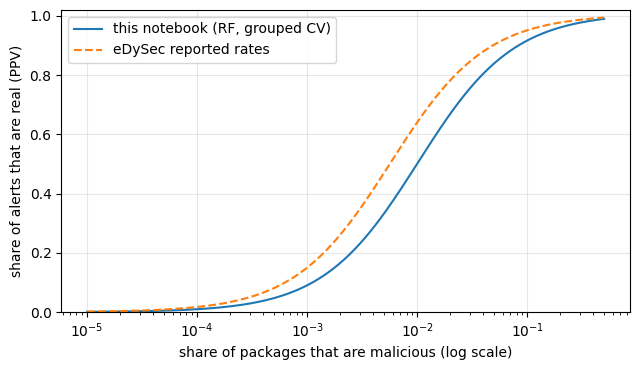

In [18]:
pis = np.logspace(-5, np.log10(0.5), 200)
fig, ax = plt.subplots(figsize=(6.5, 3.8))
ax.plot(pis, [ppv(s["TPR"], s["FPR"], p) for p in pis], label="this notebook (RF, grouped CV)")
ax.plot(pis, [ppv(0.9898, 0.0056, p) for p in pis], "--", label="eDySec reported rates")
ax.set_xscale("log")
ax.set_xlabel("share of packages that are malicious (log scale)")
ax.set_ylabel("share of alerts that are real (PPV)")
ax.set_ylim(0, 1.02)
ax.grid(alpha=.3)
ax.legend()
plt.tight_layout()
plt.show()

**Caveat.** This assumes the benign packages in QUT-DV25 look like PyPI's real benign packages. That is unproven, so treat these as illustrations of the base-rate effect, not forecasts.